# Phase 1: Data Understanding

This notebook performs an initial understanding of the European Credit Card
Fraud Detection dataset before exploratory data analysis, preprocessing, and
model development.

The main objectives are to:

- Confirm that the raw dataset is available and readable.
- Inspect the dataset structure, columns, data types, and memory usage.
- Validate the expected schema and target labels.
- Examine missing values and duplicate records.
- Understand the severe class imbalance.
- Analyze transaction amounts and elapsed-time values.
- Save a structured Phase 1 summary for later project phases.

The original dataset is only read in this notebook. It is not modified,
cleaned, resampled, or used to train a model.

In [1]:
import json
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Imports and project configuration

This cell imports the required libraries and defines the project paths,
target column, random seed, and output directories.

The notebook uses:

- `pandas` and `NumPy` for data handling and numerical analysis.
- `Matplotlib` and `Seaborn` for visualization.
- `pathlib` for portable file-path handling.
- `logging` for clear execution messages.

The raw dataset is expected at `data/raw/creditcard.csv`. The target variable
is `Class`, where `0` represents a legitimate transaction and `1` represents
a fraudulent transaction.

In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_RAW_DIR = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

RAW_DATA_PATH = DATA_RAW_DIR / "creditcard.csv"

TARGET_COLUMN = "Class"
RANDOM_SEED = 42

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
DATA_PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
)

logger = logging.getLogger(__name__)

logger.info("Project root: %s", PROJECT_ROOT)
logger.info("Raw dataset path: %s", RAW_DATA_PATH)

2026-11-01 08:30:52,121 | INFO | Project root: c:\Users\use\Desktop\Credit Card Fraud Detection
2026-11-01 08:30:52,124 | INFO | Raw dataset path: c:\Users\use\Desktop\Credit Card Fraud Detection\data\raw\creditcard.csv


## Validate the raw dataset

Before loading the data, this cell checks that the expected raw CSV file
exists and has a `.csv` extension.

If the file is missing or incorrectly named, the notebook stops with a clear
error message. This prevents later cells from silently operating on an
incorrect or unavailable dataset.

The original dataset is never overwritten or modified.

In [3]:
def validate_raw_dataset_path(file_path: Path) -> None:
    """Validate that the raw dataset file exists and is a CSV file."""
    if not file_path.exists():
        raise FileNotFoundError(
            f"Raw dataset not found at: {file_path}. "
            "Place creditcard.csv inside data/raw/."
        )

    if file_path.suffix.lower() != ".csv":
        raise ValueError(
            f"Expected a CSV file, but found: {file_path.name}"
        )


validate_raw_dataset_path(RAW_DATA_PATH)
logger.info("Raw dataset file validated successfully.")

2026-11-01 08:34:00,749 | INFO | Raw dataset file validated successfully.


## Load the raw dataset

This cell loads the original credit card fraud dataset into a pandas
DataFrame.

The loading function also handles two common file problems:

- An empty CSV file.
- A malformed or unreadable CSV file.

After loading, the notebook records the dataset shape. At this stage, the
dataset is only read; no cleaning, transformation, or model training is
performed.

In [4]:
def load_raw_dataset(file_path: Path) -> pd.DataFrame:
    """Load the raw credit card fraud dataset without modifying it."""
    try:
        dataframe = pd.read_csv(file_path)
    except pd.errors.EmptyDataError as exc:
        raise ValueError(f"The dataset file is empty: {file_path}") from exc
    except pd.errors.ParserError as exc:
        raise ValueError(f"Unable to parse the CSV file: {file_path}") from exc

    if dataframe.empty:
        raise ValueError("The loaded dataset contains no rows.")

    return dataframe


creditcard_df = load_raw_dataset(RAW_DATA_PATH)

logger.info("Dataset loaded successfully.")
logger.info("Dataset shape: %s rows, %s columns", *creditcard_df.shape)


2026-11-01 08:34:18,259 | INFO | Dataset loaded successfully.
2026-11-01 08:34:18,261 | INFO | Dataset shape: 284807 rows, 31 columns


## Dataset overview

This cell displays the basic structure of the dataset:

- Number of rows and columns.
- Column names.
- Data types.
- Approximate memory usage.

The dataset is expected to contain:

- `Time`: elapsed seconds since the first transaction.
- `V1` to `V28`: anonymized PCA-transformed numerical features.
- `Amount`: transaction amount.
- `Class`: fraud label, where `0` is legitimate and `1` is fraudulent.

In [5]:
def display_dataset_overview(dataframe: pd.DataFrame) -> None:
    """Display essential structural information about the dataset."""
    print("Dataset shape:")
    print(f"Rows: {dataframe.shape[0]:,}")
    print(f"Columns: {dataframe.shape[1]}")

    print("\nColumn names:")
    print(list(dataframe.columns))

    print("\nData types:")
    print(dataframe.dtypes.to_string())

    print("\nMemory usage:")
    print(f"{dataframe.memory_usage(deep=True).sum() / 1024**2:.2f} MB")


display_dataset_overview(creditcard_df)

Dataset shape:
Rows: 284,807
Columns: 31

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Data types:
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64

Memory usage:
67.36 MB


## Preview the first records

This cell displays the first few rows of the dataset.

This preview helps confirm that the file was loaded correctly and that the
columns contain the expected numerical values. It does not imply anything
about transaction quality or fraud status.

In [6]:
creditcard_df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Validate dataset schema and target labels

This cell validates that the dataset contains the expected columns and that
the target variable contains only the valid labels `0` and `1`.

The validation checks:

- Presence of `Time`, `V1`–`V28`, `Amount`, and `Class`.
- Unexpected additional columns.
- Presence of the `Class` target column.
- Invalid target labels.

Schema validation is important because later preprocessing, modeling, and
inference steps depend on a consistent feature structure.

In [7]:
EXPECTED_COLUMNS = ["Time", *[f"V{i}" for i in range(1, 29)], "Amount", "Class"]
EXPECTED_TARGET_VALUES = {0, 1}


def validate_dataset_schema(
    dataframe: pd.DataFrame,
    expected_columns: list[str],
    target_column: str,
    expected_target_values: set[int],
) -> None:
    """Validate expected columns, target presence, and target labels."""
    missing_columns = set(expected_columns) - set(dataframe.columns)
    unexpected_columns = set(dataframe.columns) - set(expected_columns)

    if missing_columns:
        raise ValueError(f"Missing expected columns: {sorted(missing_columns)}")

    if unexpected_columns:
        logger.warning("Unexpected columns detected: %s", sorted(unexpected_columns))

    if target_column not in dataframe.columns:
        raise ValueError(f"Target column '{target_column}' is missing.")

    invalid_target_values = set(dataframe[target_column].unique()) - expected_target_values
    if invalid_target_values:
        raise ValueError(
            f"Target column contains unexpected values: {sorted(invalid_target_values)}"
        )

    logger.info("Dataset schema and target labels validated successfully.")


validate_dataset_schema(
    dataframe=creditcard_df,
    expected_columns=EXPECTED_COLUMNS,
    target_column=TARGET_COLUMN,
    expected_target_values=EXPECTED_TARGET_VALUES,
)

2026-11-01 08:34:56,568 | INFO | Dataset schema and target labels validated successfully.


## Data quality summary

This cell calculates:

- Total rows and columns.
- Missing values per column.
- Total missing values.
- Duplicate row count.
- Duplicate row percentage.

No missing values are imputed and no duplicate rows are removed in this
phase. The purpose is to document data-quality findings so that later
preprocessing decisions can be made deliberately rather than automatically.

In [8]:
def summarize_data_quality(dataframe: pd.DataFrame) -> dict:
    """Calculate missing-value and duplicate-row summaries."""
    missing_counts = dataframe.isnull().sum()
    missing_percentages = dataframe.isnull().mean() * 100

    duplicate_count = int(dataframe.duplicated().sum())
    duplicate_percentage = duplicate_count / len(dataframe) * 100

    quality_summary = {
        "total_rows": len(dataframe),
        "total_columns": dataframe.shape[1],
        "columns_with_missing_values": missing_counts[missing_counts > 0].to_dict(),
        "total_missing_values": int(missing_counts.sum()),
        "duplicate_row_count": duplicate_count,
        "duplicate_row_percentage": duplicate_percentage,
    }

    return quality_summary


data_quality_summary = summarize_data_quality(creditcard_df)

print("Data quality summary:")
print(json.dumps(data_quality_summary, indent=2, default=str))

Data quality summary:
{
  "total_rows": 284807,
  "total_columns": 31,
  "columns_with_missing_values": {},
  "total_missing_values": 0,
  "duplicate_row_count": 1081,
  "duplicate_row_percentage": 0.379555277784605
}


## Class distribution and imbalance

This cell calculates the number and percentage of legitimate and fraudulent
transactions.

The dataset is highly imbalanced:

- `Class = 0`: legitimate transaction.
- `Class = 1`: fraudulent transaction.

Because fraudulent transactions are rare, accuracy alone is not a meaningful
evaluation metric. A model that predicts every transaction as legitimate could
achieve very high accuracy while detecting no fraud.

For this reason, later phases use metrics such as precision, recall, F1-score,
PR-AUC, ROC-AUC, and confusion matrices.

In [9]:
def summarize_class_distribution(
    dataframe: pd.DataFrame,
    target_column: str,
) -> pd.DataFrame:
    """Calculate class counts, percentages, and imbalance ratio."""
    class_counts = dataframe[target_column].value_counts().sort_index()
    class_percentages = dataframe[target_column].value_counts(normalize=True).sort_index() * 100

    legitimate_count = int(class_counts.get(0, 0))
    fraudulent_count = int(class_counts.get(1, 0))

    imbalance_ratio = (
        legitimate_count / fraudulent_count if fraudulent_count > 0 else np.inf
    )

    summary = pd.DataFrame(
        {
            "count": class_counts,
            "percentage": class_percentages,
        }
    )
    summary.index = summary.index.map({0: "Legitimate (0)", 1: "Fraudulent (1)"})
    summary["imbalance_ratio_legitimate_to_fraud"] = np.nan
    summary.loc["Fraudulent (1)", "imbalance_ratio_legitimate_to_fraud"] = imbalance_ratio

    return summary


class_distribution_summary = summarize_class_distribution(
    dataframe=creditcard_df,
    target_column=TARGET_COLUMN,
)

class_distribution_summary

,count,percentage,imbalance_ratio_legitimate_to_fraud
Class,,,
Legitimate (0),284315,99.827251,NaN
Fraudulent (1),492,0.172749,577.876016


## Visualize class distribution

This cell creates two charts:

1. The number of legitimate and fraudulent transactions.
2. The percentage of legitimate and fraudulent transactions.

The charts make the severe class imbalance visible. The figure is saved to
`reports/figures/class_distribution.png` for use in later reporting and
documentation.

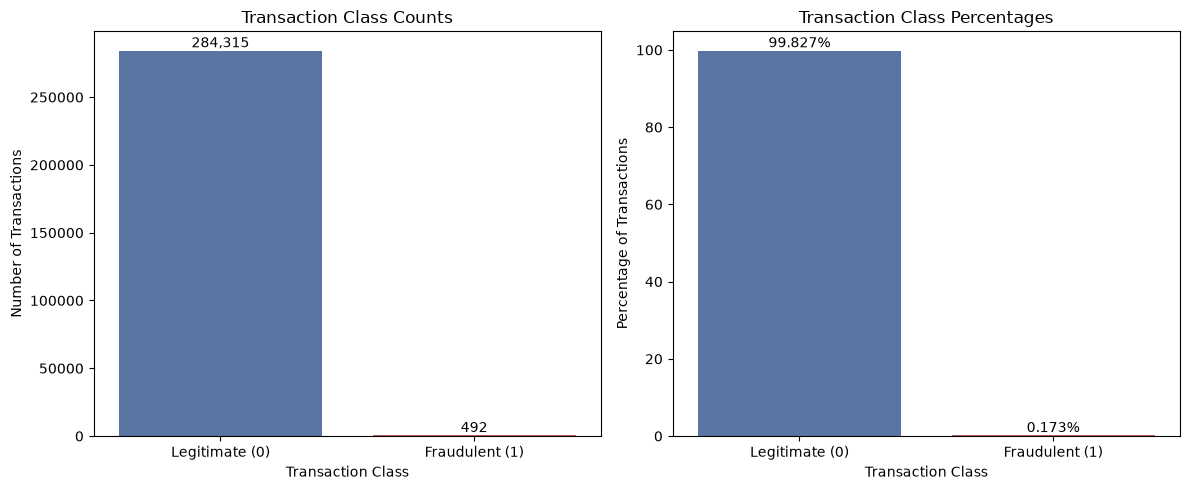

2026-11-01 08:35:34,654 | INFO | Class distribution figure saved to: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\figures\class_distribution.png


In [10]:
def plot_class_distribution(
    dataframe: pd.DataFrame,
    target_column: str,
    output_path: Path,
) -> None:
    """Create count and percentage charts for the target variable."""
    class_counts = dataframe[target_column].value_counts().sort_index()
    class_percentages = dataframe[target_column].value_counts(normalize=True).sort_index() * 100

    labels = ["Legitimate (0)", "Fraudulent (1)"]

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    sns.barplot(
        x=labels,
        y=class_counts.values,
        hue=labels,
        palette=["#4C72B0", "#C44E52"],
        legend=False,
        ax=axes[0],
    )
    axes[0].set_title("Transaction Class Counts")
    axes[0].set_xlabel("Transaction Class")
    axes[0].set_ylabel("Number of Transactions")

    for index, value in enumerate(class_counts.values):
        axes[0].text(
            index,
            value,
            f"{value:,}",
            ha="center",
            va="bottom",
        )

    sns.barplot(
        x=labels,
        y=class_percentages.values,
        hue=labels,
        palette=["#4C72B0", "#C44E52"],
        legend=False,
        ax=axes[1],
    )
    axes[1].set_title("Transaction Class Percentages")
    axes[1].set_xlabel("Transaction Class")
    axes[1].set_ylabel("Percentage of Transactions")

    for index, value in enumerate(class_percentages.values):
        axes[1].text(
            index,
            value,
            f"{value:.3f}%",
            ha="center",
            va="bottom",
        )

    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


class_distribution_figure_path = FIGURES_DIR / "class_distribution.png"

plot_class_distribution(
    dataframe=creditcard_df,
    target_column=TARGET_COLUMN,
    output_path=class_distribution_figure_path,
)

logger.info("Class distribution figure saved to: %s", class_distribution_figure_path)

## Numerical feature summary

This cell generates descriptive statistics for all numerical columns,
including count, mean, standard deviation, minimum, maximum, quartiles,
missing-value count, and number of unique values.

These statistics provide an initial view of feature scales and distributions.
They do not determine feature importance, and no features are removed or
transformed at this stage.

In [11]:
def generate_numerical_summary(dataframe: pd.DataFrame) -> pd.DataFrame:
    """Generate descriptive statistics for numerical columns."""
    numerical_columns = dataframe.select_dtypes(include=np.number).columns

    summary = dataframe[numerical_columns].describe().T
    summary["missing_values"] = dataframe[numerical_columns].isnull().sum()
    summary["unique_values"] = dataframe[numerical_columns].nunique()

    return summary


numerical_summary = generate_numerical_summary(creditcard_df)
numerical_summary

,count,mean,std,min,25%,50%,75%,max,missing_values,unique_values
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000,0,124592
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930,0,275663
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729,0,275663
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558,0,275663
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344,0,275663
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666,0,275663
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626,0,275663
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494,0,275663
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208,0,275663
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995,0,275663


## Transaction amount analysis by class

This cell compares transaction amounts for legitimate and fraudulent
transactions.

For each class, it calculates:

- Count.
- Mean.
- Median.
- Standard deviation.
- Minimum and maximum.
- 25th, 75th, 95th, and 99th percentiles.

An unusual transaction amount does not automatically mean that a transaction
is fraudulent. Legitimate transactions can also have large amounts, and
fraudulent transactions can have small amounts.

In [12]:
def summarize_amount_by_class(
    dataframe: pd.DataFrame,
    target_column: str,
    amount_column: str = "Amount",
) -> pd.DataFrame:
    """Calculate transaction amount statistics separately for each class."""
    return (
        dataframe.groupby(target_column)[amount_column]
        .agg(
            count="count",
            mean="mean",
            median="median",
            std="std",
            minimum="min",
            maximum="max",
            p25=lambda series: series.quantile(0.25),
            p75=lambda series: series.quantile(0.75),
            p95=lambda series: series.quantile(0.95),
            p99=lambda series: series.quantile(0.99),
        )
        .rename(index={0: "Legitimate (0)", 1: "Fraudulent (1)"})
    )


amount_by_class_summary = summarize_amount_by_class(
    dataframe=creditcard_df,
    target_column=TARGET_COLUMN,
)

amount_by_class_summary

,count,mean,median,std,minimum,maximum,p25,p75,p95,p99
Class,,,,,,,,,,
Legitimate (0),284315,88.291022,22.00,250.105092,0.0,25691.16,5.65,77.05,364.409,1016.9664
Fraudulent (1),492,122.211321,9.25,256.683288,0.0,2125.87,1.00,105.89,640.905,1357.4279


## Time feature summary

This cell summarizes the `Time` column, which represents elapsed seconds from
the first transaction in the dataset.

The summary includes:

- Minimum and maximum elapsed time.
- Total observed duration in hours.
- Mean and median elapsed time.
- Standard deviation.

The `Time` column is not a calendar timestamp. Therefore, it should not be
interpreted as an actual date, time of day, or day of the week.

In [13]:
def summarize_time_feature(
    dataframe: pd.DataFrame,
    time_column: str = "Time",
) -> dict:
    """Calculate basic elapsed-time statistics."""
    time_values = dataframe[time_column]

    return {
        "minimum_seconds": float(time_values.min()),
        "maximum_seconds": float(time_values.max()),
        "duration_hours": float((time_values.max() - time_values.min()) / 3600),
        "mean_seconds": float(time_values.mean()),
        "median_seconds": float(time_values.median()),
        "standard_deviation_seconds": float(time_values.std()),
    }


time_summary = summarize_time_feature(creditcard_df)

print("Time feature summary:")
print(json.dumps(time_summary, indent=2))

Time feature summary:
{
  "minimum_seconds": 0.0,
  "maximum_seconds": 172792.0,
  "duration_hours": 47.99777777777778,
  "mean_seconds": 94813.85957508067,
  "median_seconds": 84692.0,
  "standard_deviation_seconds": 47488.14595456617
}


## Build and save Phase 1 summary

This cell combines the main findings from the notebook into a structured JSON
summary.

The summary records:

- Dataset dimensions and feature columns.
- Target-column definition.
- Data-quality findings.
- Class distribution and imbalance ratio.
- Transaction-amount statistics by class.
- Elapsed-time statistics.
- Important dataset limitations.

The summary is saved to:

```text
reports/phase1_data_understanding_summary.json
```

This file provides a reproducible record of the initial dataset-understanding
phase and can support later preprocessing, modeling, and reporting decisions.

In [14]:
def build_phase1_summary(
    dataframe: pd.DataFrame,
    quality_summary: dict,
    class_summary: pd.DataFrame,
    amount_summary: pd.DataFrame,
    time_summary: dict,
) -> dict:
    """Create a structured Phase 1 dataset-understanding summary."""
    return {
        "dataset_file": RAW_DATA_PATH.name,
        "row_count": int(dataframe.shape[0]),
        "column_count": int(dataframe.shape[1]),
        "feature_columns": [column for column in dataframe.columns if column != TARGET_COLUMN],
        "target_column": TARGET_COLUMN,
        "target_classes": {
            "0": "Legitimate transaction",
            "1": "Fraudulent transaction",
        },
        "data_quality": quality_summary,
        "class_distribution": {
            "legitimate_count": int(class_summary.loc["Legitimate (0)", "count"]),
            "fraudulent_count": int(class_summary.loc["Fraudulent (1)", "count"]),
            "legitimate_percentage": float(class_summary.loc["Legitimate (0)", "percentage"]),
            "fraudulent_percentage": float(class_summary.loc["Fraudulent (1)", "percentage"]),
            "fraud_to_legitimate_ratio": float(
                class_summary.loc["Fraudulent (1)", "count"]
                / class_summary.loc["Legitimate (0)", "count"]
            ),
        },
        "amount_statistics_by_class": amount_summary.to_dict(),
        "time_statistics": time_summary,
        "dataset_limitations": [
            "V1 to V28 are anonymized PCA-transformed features with no known business meanings.",
            "The dataset does not include customer, merchant, location, or transaction-category information.",
            "Time is elapsed seconds from the first transaction, not a calendar timestamp.",
            "The dataset is extremely imbalanced, so accuracy alone is not an appropriate evaluation metric.",
        ],
    }


phase1_summary = build_phase1_summary(
    dataframe=creditcard_df,
    quality_summary=data_quality_summary,
    class_summary=class_distribution_summary,
    amount_summary=amount_by_class_summary,
    time_summary=time_summary,
)

phase1_summary_path = REPORTS_DIR / "phase1_data_understanding_summary.json"

with phase1_summary_path.open("w", encoding="utf-8") as file:
    json.dump(phase1_summary, file, indent=2, default=str)

logger.info("Phase 1 summary saved to: %s", phase1_summary_path)

2026-11-01 08:36:06,852 | INFO | Phase 1 summary saved to: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\phase1_data_understanding_summary.json


## Final output validation

This final cell verifies that the expected outputs were created:

- `reports/figures/class_distribution.png`
- `reports/phase1_data_understanding_summary.json`

If either output is missing, the notebook raises an error instead of silently
claiming successful completion.

At this point, Phase 1 data understanding is complete. The dataset has been
inspected and documented, but no cleaning, feature engineering, resampling,
model training, or threshold selection has been performed.

In [15]:
if class_distribution_figure_path.exists():
    logger.info("Generated figure exists: %s", class_distribution_figure_path)
else:
    raise FileNotFoundError(
        f"Expected figure was not created: {class_distribution_figure_path}"
    )

if phase1_summary_path.exists():
    logger.info("Generated summary exists: %s", phase1_summary_path)
else:
    raise FileNotFoundError(
        f"Expected summary was not created: {phase1_summary_path}"
    )

print("Phase 1 data understanding notebook completed successfully.")

2026-11-01 08:36:17,227 | INFO | Generated figure exists: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\figures\class_distribution.png
2026-11-01 08:36:17,230 | INFO | Generated summary exists: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\phase1_data_understanding_summary.json


Phase 1 data understanding notebook completed successfully.
